# Historial: Etapa 3 en la versión de Thiago (partición contigua)
Enfoque alternativo que trabajamos en paralelo: partición contigua 80/10/10 (Test es el último 10 % del cuento), secuencias de 48 caracteres con paso 5 en Train, una LSTM que predice cada posición (Embedding 50, LSTM 96, Dense 48; 67.638 parámetros), perplejidad como métrica principal y 1 semilla.

**Resultados en su partición:** ganador `lstm_combined_l1_l2` (Dropout, L1/L2 y Early Stopping), con 46,75 % de accuracy y perplejidad 6,33 en Dev, y 44,97 % en su Test.

**Por qué no se compara con el notebook principal:** otra partición, otra tarea de salida y una sola semilla. Del notebook principal tomamos de acá la estructura de la Etapa 5, el análisis por frecuencia y por función del carácter (secciones 4.2 y 4.3) y varias ideas de mejoras y mitigación. El código de los módulos está en `src/` de la rama `dev_thiago`; este notebook queda como registro.

# Etapa 3 — Arquitectura LSTM y Embeddings de Caracteres
### Objetivos y criterios de éxito

## 1. Configuración, Semillas e Imports Modulares

In [1]:
import sys
from pathlib import Path
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

# Resolución dinámica de la raíz del proyecto
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Imports modulares del proyecto
from src.utils.config import (
    BATCH_SIZE,
    CHECKPOINTS_DIR,
    EVALUATION_CONFIG,
    MODEL_CONFIGS,
    PROCESSED_DATA_PATH,
    RAW_DATA_PATH,
    SEED,
    SEQ_LENGTH,
    STAGE_2_REFERENCE,
    TRAINING_CONFIG,
)
from src.utils.types import EvaluationResult, HardExample, TrainResult
from src.data.preprocess import clean_txt, read_text
from src.data.tokenizer import build_tokenizer
from src.data.dataset import create_dataset
from src.models.lstm import (
    build_lstm_model,
    build_pretrained_embedding_matrix,
    generate_text,
)
from src.training.train import evaluate_model, extract_hard_examples, train_model
from src.utils.plots import (
    format_comparison_table,
    format_hard_examples_table,
    plot_perplexity_comparison,
    plot_training_curves,
)

# Reproducibilidad y estilo visual
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print(f"TensorFlow: {tf.__version__} | Seed: {SEED} | SeqLen: {SEQ_LENGTH} | Batch: {BATCH_SIZE}")
print(f"Configuraciones disponibles: {list(MODEL_CONFIGS.keys())}")
print(f"Configuraciones de tempertatura para generar texto: {EVALUATION_CONFIG['generation_temperatures']}")

TensorFlow: 2.21.0 | Seed: 42 | SeqLen: 48 | Batch: 16
Configuraciones disponibles: ['lstm_baseline', 'lstm_reg_early_stop', 'lstm_reg_dropout', 'lstm_reg_l2', 'lstm_reg_l1', 'lstm_combined_scratch', 'lstm_combined_l1_l2', 'lstm_combined_glove']
Configuraciones de tempertatura para generar texto: [0.3, 0.7, 1.0, 1.1]


## 2. Preparación del Pipeline de Datos

In [2]:
clean_txt(RAW_DATA_PATH, PROCESSED_DATA_PATH)
text = read_text(PROCESSED_DATA_PATH)

tokenizer = build_tokenizer(text)
vocab_size = len(tokenizer.get_vocabulary())
ids = tokenizer.encode(text)

# Partición contigua temporal (80 / 10 / 10)
total_tokens = len(ids)
train_end = int(total_tokens * 0.80)
dev_end = int(total_tokens * 0.90)

train_ids = ids[:train_end]
dev_ids = ids[train_end:dev_end]
test_ids = ids[dev_end:]

ds_train = create_dataset(train_ids, shuffle=True)
ds_dev = create_dataset(dev_ids, shuffle=False)
ds_test = create_dataset(test_ids, shuffle=False)

print(f"Vocabulario |V|: {vocab_size} símbolos")
print(f"Tokens -> Train: {len(train_ids):,} | Dev: {len(dev_ids):,} | Test: {len(test_ids):,}")

[preprocess] El texto limpio ya existe en 'data\processed\The_Festival_clean.txt'.
[tokenizer] Vocabulario ordenado: ['\n', ' ', '"', "'", ',', '-', '.', '0', '1', '2', '5', '6', '8', '9', ':', ';', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'W', 'Y', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '—'] 
[tokenizer] Vocabulario con 65 caracteres únicos.
Vocabulario |V|: 66 símbolos
Tokens -> Train: 16,164 | Dev: 2,020 | Test: 2,021


## 3. Vectores semánticos: Embeddings desde Cero vs. Pre-entrenados

In [3]:
# Pre-cálculo y cacheo de matrices de embeddings pre-entrenadas por dimensión requerida
pretrained_matrices: dict[int, np.ndarray] = {}

for cfg in MODEL_CONFIGS.values():
    if cfg["use_pretrained"] and cfg["embedding_dim"] not in pretrained_matrices:
        dim = cfg["embedding_dim"]
        pretrained_matrices[dim] = build_pretrained_embedding_matrix(
            vocabulary=tokenizer.get_vocabulary(),
            embedding_dim=dim,
        )

for dim, mat in pretrained_matrices.items():
    print(f"Matriz pre-entrenada (dim={dim}): shape={mat.shape}, mean={mat.mean():.4f}, std={mat.std():.4f}")

# Inspección rápida de las configuraciones a entrenar
for name, cfg in MODEL_CONFIGS.items():
    print(
        f"- {name}: emb={cfg['embedding_dim']}, rnn={cfg['rnn_units']}, "
        f"dense={cfg['dense_units']}, pretrained={cfg['use_pretrained']}, "
        f"trainable_emb={cfg['trainable_embedding']}, l1={cfg['l1_reg']}, l2={cfg['l2_reg']}, "
        f"early_stop={cfg['use_early_stopping']}, lr={cfg['learning_rate']}"
    )

[lstm] GloVe 'glove-wiki-gigaword-50' cargado: 63/66 símbolos cubiertos (95.5%).
Matriz pre-entrenada (dim=50): shape=(66, 50), mean=0.0764, std=0.7211
- lstm_baseline: emb=50, rnn=96, dense=48, pretrained=False, trainable_emb=True, l1=0.0, l2=0.0, early_stop=False, lr=0.001
- lstm_reg_early_stop: emb=50, rnn=96, dense=48, pretrained=False, trainable_emb=True, l1=0.0, l2=0.0, early_stop=True, lr=0.001
- lstm_reg_dropout: emb=50, rnn=96, dense=48, pretrained=False, trainable_emb=True, l1=0.0, l2=0.0, early_stop=False, lr=0.001
- lstm_reg_l2: emb=50, rnn=96, dense=48, pretrained=False, trainable_emb=True, l1=0.0, l2=0.0001, early_stop=False, lr=0.001
- lstm_reg_l1: emb=50, rnn=96, dense=48, pretrained=False, trainable_emb=True, l1=1e-05, l2=0.0, early_stop=False, lr=0.001
- lstm_combined_scratch: emb=50, rnn=96, dense=48, pretrained=False, trainable_emb=True, l1=0.0, l2=0.0001, early_stop=True, lr=0.001
- lstm_combined_l1_l2: emb=50, rnn=96, dense=48, pretrained=False, trainable_emb=True

## 4. Construcción y Entrenamiento Iterativo de Modelos LSTM

In [4]:
EPOCHS_OVERRIDE: int | None = None

results_dict: dict[str, TrainResult] = {}
trained_models: dict[str, tf.keras.Model] = {}

for model_key, model_cfg in MODEL_CONFIGS.items():
    print(f"\n=== Entrenando: {model_key} ===")
    print(f"Descripción: {model_cfg['description']}")

    pre_mat = pretrained_matrices.get(model_cfg["embedding_dim"]) if model_cfg["use_pretrained"] else None
    model = build_lstm_model(
        vocab_size=vocab_size,
        config=model_cfg,
        pretrained_matrix=pre_mat,
        model_name=model_key,
    )

    if model_key == "lstm_baseline":
        model.summary()

    ckpt_path = CHECKPOINTS_DIR / f"{model_key}.weights.h5"
    train_res = train_model(
        model=model,
        train_ds=ds_train,
        dev_ds=ds_dev,
        config=model_cfg,
        epochs=EPOCHS_OVERRIDE,
        training_config=TRAINING_CONFIG,
        checkpoint_path=ckpt_path,
        log_every_n_epochs=10,
    )

    results_dict[model_key] = train_res
    trained_models[model_key] = model

    print(
        f"-> Mejor época: {train_res['best_epoch']}/{train_res['epochs_trained']} | "
        f"Val Loss: {train_res['best_val_loss']:.4f} | "
        f"Val PPL: {train_res['best_val_perplexity']:.2f} | "
        f"Val Acc: {train_res['best_val_accuracy'] * 100:.2f}%"
    )


=== Entrenando: lstm_baseline ===
Descripción: Referencia base sin regularización ni early stopping (Scratch)


Model: "lstm_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ char_embedding (Embedding)      │ (None, None, 50)       │         3,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ recurrent_lstm (LSTM)           │ (None, None, 96)       │        56,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, None, 48)       │         4,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits_output (Dense)           │ (None, None, 66)       │         3,234 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,638 (264.21 KB)

 Trainable params: 67,638 (264.21 KB)

 Non-trainable params: 0 (0.00 B)

Época 10/30 — loss: 1.7332 | acc: 0.4840 | ppl: 5.66 | val_loss: 1.9486 | val_acc: 0.4395 | val_ppl: 7.02 | lr: 1.0e-03

Epoch 15: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 18: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Época 20/30 — loss: 1.3955 | acc: 0.5770 | ppl: 4.04 | val_loss: 1.9926 | val_acc: 0.4588 | val_ppl: 7.33 | lr: 2.5e-04

Epoch 21: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 24: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 27: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 30: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.
Época 30/30 — loss: 1.3469 | acc: 0.5914 | ppl: 3.85 | val_loss: 2.0140 | val_acc: 0.4588 | val_ppl: 7.49 | lr: 3.1e-05
-> Mejor época: 12/30 | Val Loss: 1.9445 | Val PPL: 6.99 | Val Acc: 45.12%

=== Entrenando: lstm_reg_early_stop ===
Descripción: Ablación 1: Solo Early Stopping sobre model

## 5. Comparativa Integral y Evaluación Final en Test

#### TABLA COMPARATIVA INTEGRAL — ETAPA 3 (MODELOS LSTM Y EMBEDDINGS)

,Modelo,Embeddings,Dim (E/L/D),Dropout (In/Rec),L1 / L2,LR,Early Stop,Parámetros (Entr.),Época,Val Loss,Val PPL,Val BPC,Val Acc,Mejora PPL vs E2
0,lstm_baseline,Desde cero (Scratch),50/96/48,0.0/0.0,0/0,1e-03,No,"67,638 (67,638)",12/30,1.9445,6.99,2.805,0.4512,+0.71%
1,lstm_reg_early_stop,Desde cero (Scratch),50/96/48,0.0/0.0,0/0,1e-03,Sí,"67,638 (67,638)",13/23,1.9369,6.94,2.794,0.4395,+1.42%
2,lstm_reg_dropout,Desde cero (Scratch),50/96/48,0.2/0.1,0/0,1e-03,No,"67,638 (67,638)",22/30,1.8608,6.43,2.685,0.4599,+8.66%
3,lstm_reg_l2,Desde cero (Scratch),50/96/48,0.0/0.0,0/1e-04,1e-03,No,"67,638 (67,638)",17/30,1.9231,6.84,2.774,0.4512,+2.84%
4,lstm_reg_l1,Desde cero (Scratch),50/96/48,0.0/0.0,1e-05/0,1e-03,No,"67,638 (67,638)",14/30,1.9108,6.76,2.757,0.4456,+3.98%
5,lstm_combined_scratch,Desde cero (Scratch),50/96/48,0.2/0.1,0/1e-04,1e-03,Sí,"67,638 (67,638)",30/30,1.8602,6.42,2.684,0.4649,+8.81%
6,lstm_combined_l1_l2,Desde cero (Scratch),50/96/48,0.2/0.1,1e-05/1e-04,1e-03,Sí,"67,638 (67,638)",28/30,1.8450,6.33,2.662,0.4675,+10.09%
7,lstm_combined_glove,Pre-entrenado (Fine-tuned),50/96/48,0.2/0.1,0/1e-04,5e-04,Sí,"67,638 (67,638)",30/30,1.8691,6.48,2.697,0.4593,+7.95%


Top 3 modelos graficados (menor Val PPL): ['lstm_combined_l1_l2', 'lstm_combined_scratch', 'lstm_reg_dropout']


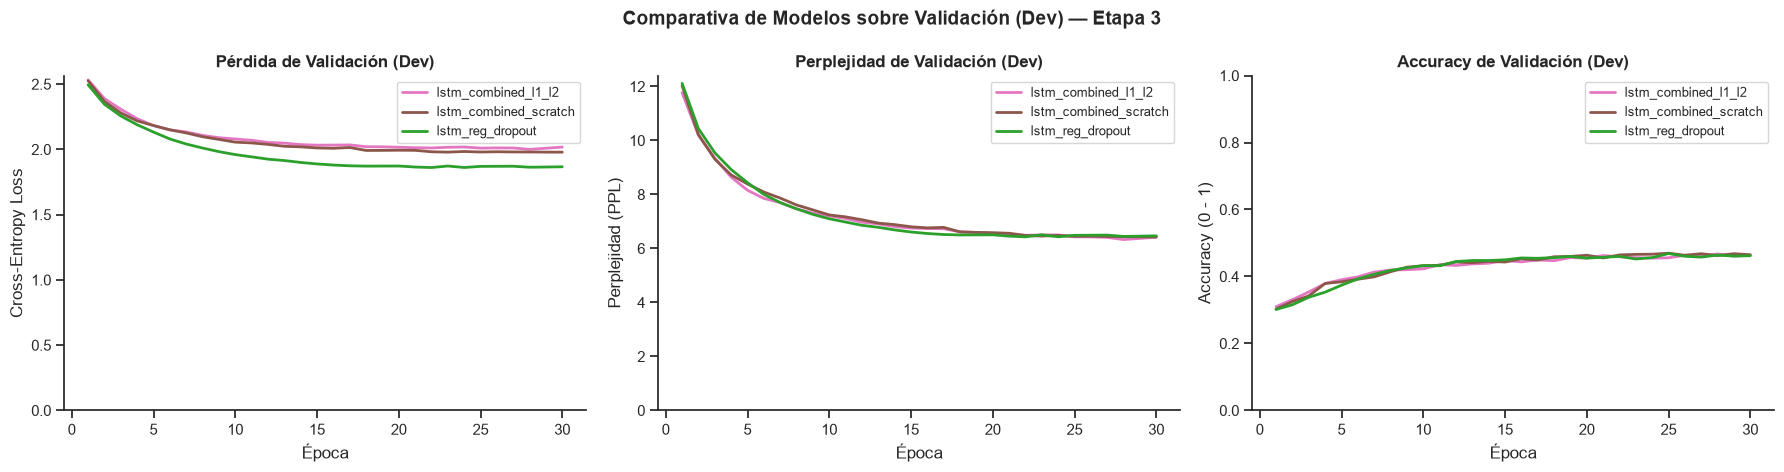

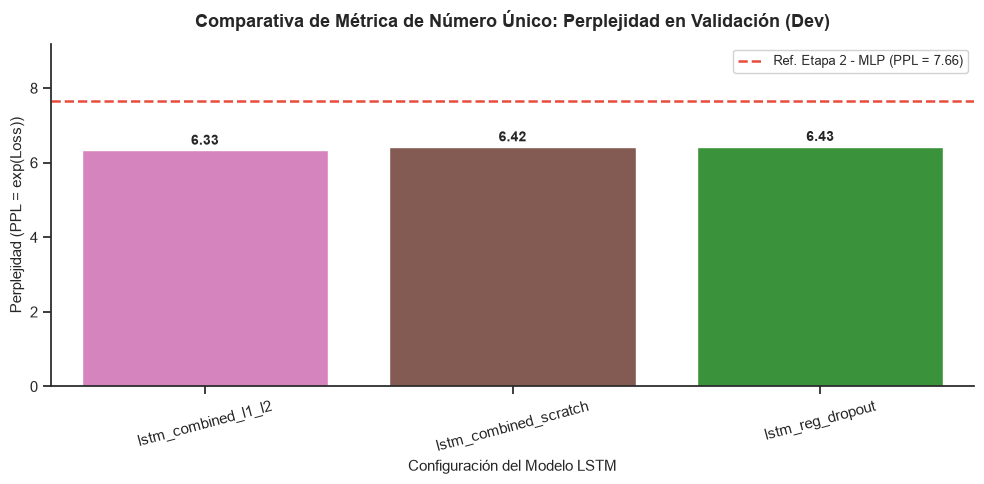


=== Evaluación Final en Test (lstm_combined_l1_l2) ===
Test Loss:                2.0097
Test Perplejidad (Única): 7.46
Test BPC:                 2.899
Test Accuracy:            44.97%
Mejora PPL vs Etapa 2:    +0.20 (+2.61%)


In [8]:
# Tabla comparativa integral (8 configuraciones) y gráficos solo para el Top 4
comparison_md = format_comparison_table(results_dict, stage2_reference=STAGE_2_REFERENCE)
top_3_keys = sorted(results_dict, key=lambda k: results_dict[k]["best_val_perplexity"])[:3]
top_3_results: dict[str, TrainResult] = {k: results_dict[k] for k in top_3_keys}
print(f"Top 3 modelos graficados (menor Val PPL): {top_3_keys}")
plot_training_curves(top_3_results)
plot_perplexity_comparison(top_3_results, stage2_reference=STAGE_2_REFERENCE)

# Selección del mejor modelo según menor Perplejidad en Validación
best_model_key = min(results_dict, key=lambda k: results_dict[k]["best_val_perplexity"])
best_model = trained_models[best_model_key]

test_metrics: EvaluationResult = evaluate_model(
    model=best_model,
    dataset=ds_test,
    stage2_reference=STAGE_2_REFERENCE,
    verbose=0,
)

print(f"\n=== Evaluación Final en Test ({best_model_key}) ===")
print(f"Test Loss:                {test_metrics['loss']:.4f}")
print(f"Test Perplejidad (Única): {test_metrics['perplexity']:.2f}")
print(f"Test BPC:                 {test_metrics['bpc']:.3f}")
print(f"Test Accuracy:            {test_metrics['accuracy'] * 100:.2f}%")
if STAGE_2_REFERENCE["val_perplexity"] > 0:
    print(
        f"Mejora PPL vs Etapa 2:    {test_metrics['perplexity_reduction_abs']:+.2f} "
        f"({test_metrics['perplexity_reduction_pct']:+.2f}%)"
    )

## 6. Auditoría de Errores: Análisis de 10 Ejemplos Difíciles

In [6]:
hard_examples: list[HardExample] = extract_hard_examples(
    model=best_model,
    dataset=ds_test,
    tokenizer=tokenizer,
    num_examples=EVALUATION_CONFIG["hard_examples_count"],
    context_window=EVALUATION_CONFIG["hard_examples_context"],
)

hard_examples_md = format_hard_examples_table(hard_examples)

#### AUDITORÍA DE ERRORES — TOP 10 EJEMPLOS DIFÍCILES

,#,Categoría,Contexto Previo,Esperado,Predicho,P(Esp.),P(Pred.),Loss
0,1,Puntuación o salto de estructura,"' They said\nsomething about a ""psychosis,'","'""'",' ',0.0000,0.9296,16.7315
1,2,Puntuación o salto de estructura,"'ard Low Latin.\n\n""The nethermost caverns,'","'""'",' ',0.0000,0.9292,15.3882
2,3,Puntuación o salto de estructura,"'al Hill, they sent me to St'",'.','a',0.0000,0.2767,14.2946
3,4,Morfología interna de palabra (vocabulario lit...,' held by no head. Wisely did I','b',' ',0.0000,0.9409,12.2190
4,5,Puntuación o salto de estructura,'it were best forgotten.\nThere was no one','—',' ',0.0000,0.8396,10.7630
5,6,Morfología interna de palabra (vocabulario lit...,'snow. There was not','h',' ',0.0001,0.8767,9.5199
6,7,Morfología interna de palabra (vocabulario lit...,"""lly sheltered copy of Alhazred's ob""",'j','e',0.0001,0.3579,9.4904
7,8,Inicio de oración o nombre propio (Mayúscula),'ything was wrong. ','E','T',0.0001,0.3466,9.4068
8,9,Inicio de oración o nombre propio (Mayúscula),'it and swell monstrous to plague it. ','G','T',0.0001,0.3233,9.0175
9,10,Morfología interna de palabra (vocabulario lit...,'nd\nhappy the town at night whose wi','z','t',0.0001,0.6349,8.9096


## 7. Generación de Texto Literario (Muestreo con Temperatura) y Conclusiones

In [9]:
seed_prompt = EVALUATION_CONFIG["generation_seed_text"]
num_chars = EVALUATION_CONFIG["generation_num_chars"]

for temp in EVALUATION_CONFIG["generation_temperatures"]:
    sample = generate_text(
        model=best_model,
        tokenizer=tokenizer,
        seed_text=seed_prompt,
        num_chars=num_chars,
        temperature=temp,
    )
    print(f"\n--- Temperatura T = {temp} ---")
    print(sample)


--- Temperatura T = 0.3 ---
The ancient town of Kingsport where had feen the throng was a saw the town the throng was the throng the charch white the that I saw the throng was the rot and the stange of the strange and the house of the sters and the stold an

--- Temperatura T = 0.7 ---
The ancient town of Kingsport of in massent where a sow the merite tulchyard. But in the old on the soint had feas not wome I saw the bast was that the high he bast no lade windst of the that and the for the lentes and which the


--- Temperatura T = 1.0 ---
The ancient town of Kingsport which I was glat out
the heckj mestexs blakness stone the
Youge
was siter, and mopping bally where not so a their the town. The hear, the figs the where couanlely once wet where me intaped
door a,
wa

--- Temperatura T = 1.1 ---
The ancient town of Kingsported
ic inso to that
bleagh-Yured bexlas, the blong, and for the mad where wempt ine in not le5ble. It was carspons to me fear
hough I banxitival tace. Fir
and pibus. 

---
## Conclusiones de la Etapa 3
### 1. Efecto de la regularización (estudio de ablación).
Con una arquitectura homogénea `50/96/48` (`67,638` parámetros) sobre un corpus pequeño (`~20,205` caracteres, `|V| = 66`):
* La LSTM sin regularización (`lstm_baseline`, `Val PPL = 6.99`) alcanza su mejor punto temprano (época `12/30`) y luego sobreajusta. 
* Entre las técnicas aisladas, **Dropout** (`lstm_reg_dropout`, `Val PPL = 6.43`) produjo el mayor salto de generalización frente a L1 (`6.76`), L2 (`6.84`) y Early Stopping (`6.94`).

### 2. Mejor configuración (ElasticNet) y mejora respecto a la Etapa 2.
La combinación de **Dropout + L1 (`1e-5`) + L2 (`1e-4`) + Early Stopping** (`lstm_combined_l1_l2`), evaluada mediante Perplejidad pura (sin incluir la penalización L1/L2 en la métrica), obtuvo:
* El mejor rendimiento en **validación**: `Val PPL = 6.33`, `Val Loss = 1.8450`, `Val BPC = 2.662`, `Val Acc = 46.75%`. 
* En **prueba**: `Test PPL = 7.46`, `Test Loss = 2.0097`, `Test BPC = 2.899`, `Test Acc = 44.97%`.
* **Mejora sobre Etapa 1 y Etapa 2:** Respecto al MLP ganador de la Etapa 2 (`MLP 128-64-32 + Dropout 0.05`, `Val PPL = 7.04`, `Val Loss = 1.9510`), la LSTM ganadora reduce la Perplejidad en **`-0.71` puntos (`+10.09%` de mejora)** (e incluso frente a la variante de menor pérdida de Etapa 2, `Dropout 0.05 + Early Stopping` con `Val PPL = 6.57`, reduce `-0.24` puntos / `+3.65%`). Frente al Baseline de la Etapa 1 (`LogisticRegression K=5`, `Val PPL = 8.05`), la reducción total alcanza **`-1.72` puntos (`+21.37%`)**.

### 3. Embeddings desde cero vs. GloVe 50d.
Aunque `glove-wiki-gigaword-50` cubrió `63/66` símbolos (`95.5%`) con una convergencia sólida (`Val PPL = 6.48`), el entrenamiento desde cero lo superó levemente:
* Embeddings Scratch (`lstm_combined_l1_l2` / `lstm_combined_scratch`): `Val PPL = 6.33` / `6.42`. 
* Embeddings pre-entrenados (`lstm_combined_glove`): `Val PPL = 6.48`.

Confirmando que en modelado *char-level* pesan más los patrones morfológicos propios del corpus que los vectores semánticos externos.
### 4. Auditoría de errores y generación de texto.
Los fallos más costosos en `ds_test` corresponden a signos de puntuación o estructura (`"`, `—`, `.`), morfología de vocabulario poco frecuente o nombres propios (*Alhazred*) e inicios de oración en mayúscula.

En la generación autorregresiva, *$T = 0.7$* ofrece el mejor equilibrio entre coherencia léxica y variedad frente a la repetición en $T = 0.3$ y los neologismos en $T \ge 1.0$.

### Límite por volumen de datos.
La convergencia hacia las épocas `28–30` y la brecha entre validación (`6.33`) y test (`7.46`) muestran que la mejora adicional está acotada principalmente por el tamaño del texto disponible más que por la cantidad de épocas o capacidad de la LSTM.